# Statistical Analysis: What Is Associated with Higher Claims?

Step 4 of the project (see `docs/methodology.md`).

Step 3 (EDA) produced six hypotheses. This notebook tests them with multiple linear regression, which estimates each variable's effect while holding the others constant, and attaches a confidence interval to each estimate.

The notebook follows the order of the work:

1. Model 1: all variables, no interaction
2. Model 2: adding the smoking × BMI 30+ interaction seen in EDA
3. A robustness check on Model 2
4. Model 3: log of claim
5. Gamma GLMs
6. Summary of the hypotheses

Things to keep in mind:

- Every coefficient is read as "holding the other variables constant".
- These are associations in data that may be synthetic, not proof of cause and effect.
- Claim units are undocumented, so amounts are shown as plain numbers.
- Simple group tests (t-tests, ANOVA) were not run separately. The regression answers the same questions while also accounting for the other variables.

In [1]:
import os
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.diagnostic import het_breuschpagan

# Run from the project root so the database path works
if Path.cwd().name == "notebooks":
    os.chdir("..")

# Load the cleaned table (1,332 rows) and close the connection
con = duckdb.connect("data/processed/insurance.duckdb", read_only=True)
df = con.sql("SELECT * FROM insurance_cleaned").df()
con.close()

# Group labels used to color the residual plots
df["group"] = (df["smoker"].map({True: "Smoker", False: "Non-smoker"})
               + ", BMI " + (df["bmi"] >= 30).map({True: "30+", False: "<30"}))

sns.set_theme(style="whitegrid")
df.shape

(1332, 11)

## 1. Model 1: all variables, no interaction

The starting point: every variable as a separate effect. `C()` tells statsmodels to treat a column as categories. It picks one category as the baseline (here: female for gender, northeast for region) and compares the others with it.

In [2]:
# Model 1: every variable on its own, no interaction
model_1 = smf.ols("claim ~ age + bmi + bloodpressure + children + smoker + diabetic + C(gender) + C(region)", data=df).fit()
print(model_1.summary())

                            OLS Regression Results                            
Dep. Variable:                  claim   R-squared:                       0.707
Model:                            OLS   Adj. R-squared:                  0.705
Method:                 Least Squares   F-statistic:                     318.7
Date:                Wed, 07 Oct 2026   Prob (F-statistic):               0.00
Time:                        09:44:43   Log-Likelihood:                -13595.
No. Observations:                1332   AIC:                         2.721e+04
Df Residuals:                    1321   BIC:                         2.727e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept              -2.26

R² is 0.707: the variables together explain about 71% of the variation in claims. The F-test (p < 0.001) shows the model does much better than predicting the average claim for everyone.

- Smoking: smokers' expected claim is about 20,700 higher (95% CI 19,700 to 21,600), by far the largest effect.
- BMI (+352 per point), blood pressure (+229 per point) and children (+681 per child) are all significant (p < 0.001).
- Region: compared with the northeast, the other three regions are about 1,950 to 2,900 lower (p ≤ 0.001). This supports the EDA observation that the northeast stands out.
- Age (p = 0.305), diabetic status (p = 0.440) and gender (p = 0.996) are not significant. Their confidence intervals include zero, so there is no evidence they are associated with claims once the other variables are held constant.

A surprise: children is significant, although the EDA box plots showed no trend. The next cell splits it by smoking status.

In [3]:
# Mean claim by number of children, non-smokers only
non_smokers = df[~df["smoker"]]
non_smokers.groupby("children")["claim"].agg(["count", "mean"]).round(0)

,count,mean
children,,
0,453,7698.0
1,263,8303.0
2,185,9493.0
3,118,9615.0
4,22,12121.0
5,17,8184.0


Among non-smokers, mean claims rise from 7,698 with no children to 12,121 with four. In EDA this was hidden, because smokers' much larger claims swamped the difference. Holding smoking constant shows the trend. The model assumes each child adds the same amount, which is an approximation: the 5-children group (17 non-smokers) does not follow the pattern.

Open question: Model 1 has no smoking × BMI interaction, which EDA suggested is important. Do the diagnostics show a problem?

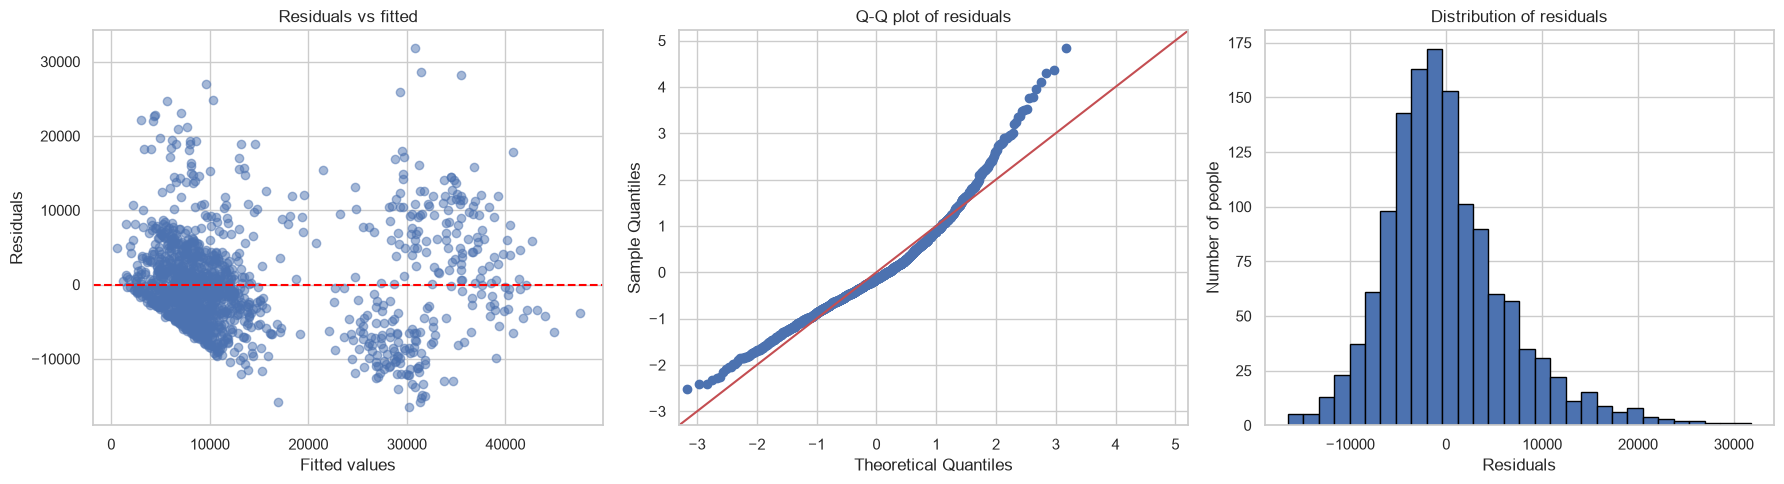

In [4]:
# Diagnostic plots for Model 1
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Residuals vs fitted: should be a shapeless cloud around 0
axes[0].scatter(model_1.fittedvalues, model_1.resid, alpha=0.5)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(xlabel="Fitted values", ylabel="Residuals", title="Residuals vs fitted")

# 2. Q-Q plot: points should follow the line if residuals are normal
sm.qqplot(model_1.resid, line="45", fit=True, ax=axes[1])
axes[1].set_title("Q-Q plot of residuals")

# 3. Histogram: should look roughly bell-shaped and centered on 0
axes[2].hist(model_1.resid, bins=30, edgecolor="black")
axes[2].set(xlabel="Residuals", ylabel="Number of people", title="Distribution of residuals")

plt.tight_layout()
plt.show()

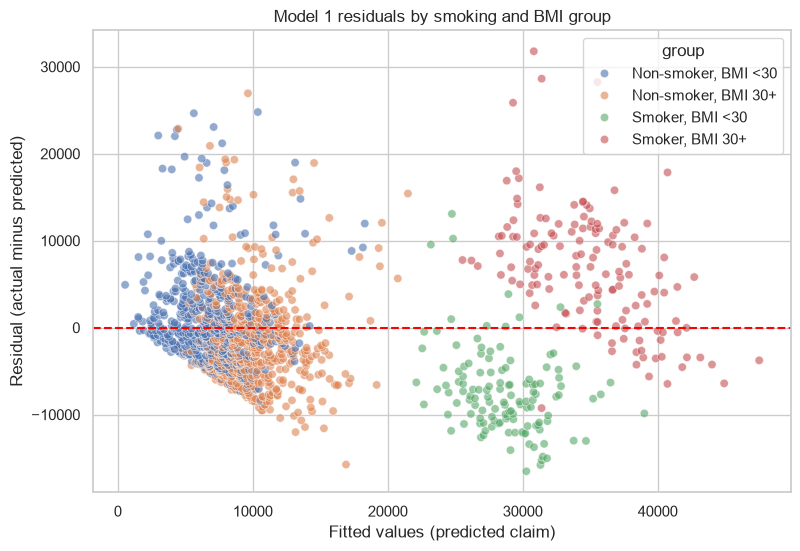

In [5]:
# Same residual plot, colored by smoking and BMI group
plt.figure(figsize=(9, 6))
sns.scatterplot(x=model_1.fittedvalues, y=model_1.resid, hue=df["group"], alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values (predicted claim)")
plt.ylabel("Residual (actual minus predicted)")
plt.title("Model 1 residuals by smoking and BMI group")
plt.show()

In [6]:
# Average residual in each group (positive = model predicts too low)
print(model_1.resid.groupby(df["group"]).agg(["count", "mean"]).round(0))

# Breusch-Pagan test: is the spread of the residuals constant? (small p = not constant)
print("Breusch-Pagan p:", round(het_breuschpagan(model_1.resid, model_1.model.exog)[1], 3))

# Skewness of the residuals (0 = symmetric, positive = long right tail)
print("Residual skewness:", round(model_1.resid.skew(), 2))

                     count    mean
group                             
Non-smoker, BMI 30+    557 -1189.0
Non-smoker, BMI <30    501  1322.0
Smoker, BMI 30+        145  6546.0
Smoker, BMI <30        129 -7358.0
Breusch-Pagan p: 0.0
Residual skewness: 0.98


The residuals vs fitted plot should be a shapeless cloud around zero. Instead it shows clear structure:

- Two clusters: non-smokers on the left and smokers on the right. The model shifts every smoker up by the same amount.
- Within the smokers there are two bands, and coloring by group shows what they are:

| Group | n | Average residual |
|---|---|---|
| Smokers, BMI 30+ | 145 | +6,546 (predicted too low) |
| Smokers, BMI under 30 | 129 | -7,358 (predicted too high) |
| Non-smokers, BMI 30+ | 557 | -1,189 |
| Non-smokers, BMI under 30 | 501 | +1,322 |

Model 1 uses one BMI slope for everyone. That slope is too flat for smokers and slightly too steep for non-smokers. This is the smoking × BMI interaction from EDA, showing up as a pattern the model misses.

- The spread of the residuals is not constant (heteroscedasticity): Breusch-Pagan p < 0.001. The coefficients are still unbiased, but the standard errors, p-values and confidence intervals may be unreliable.
- The Q-Q plot follows the line in the middle but curves away at the top: some claims are much higher than predicted (skewness 0.98). The histogram is centered on zero with a longer right tail.

Open question: does adding the smoking × BMI 30+ interaction remove the bands?

## 2. Model 2: adding smoking × BMI 30+

`smoker * bmi_30_plus` adds three terms: smoking, BMI 30+, and the two together (the interaction).

In [7]:
# New column: 1 if BMI is 30 or more (the obesity threshold), else 0
df["bmi_30_plus"] = (df["bmi"] >= 30).astype(int)

# Model 2: Model 1 plus the smoking x BMI 30+ interaction
model_2 = smf.ols("claim ~ age + bmi + bloodpressure + children + diabetic + C(gender) + C(region) + smoker * bmi_30_plus", data=df).fit()
print(model_2.summary())

                            OLS Regression Results                            
Dep. Variable:                  claim   R-squared:                       0.792
Model:                            OLS   Adj. R-squared:                  0.790
Method:                 Least Squares   F-statistic:                     418.7
Date:                Wed, 07 Oct 2026   Prob (F-statistic):               0.00
Time:                        09:44:44   Log-Likelihood:                -13367.
No. Observations:                1332   AIC:                         2.676e+04
Df Residuals:                    1319   BIC:                         2.683e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

In [8]:
# R² always rises when variables are added, so also compare measures that penalize extra variables
print("Adjusted R²:", round(model_1.rsquared_adj, 3), "vs", round(model_2.rsquared_adj, 3))
print("AIC:", round(model_1.aic), "vs", round(model_2.aic))
print("BIC:", round(model_1.bic), "vs", round(model_2.bic))

# F-test: does Model 2 improve on Model 1 by more than chance?
anova_lm(model_1, model_2)

Adjusted R²: 0.705 vs 0.79
AIC: 27212 vs 26759
BIC: 27270 vs 26827


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,1321.0,5.719688e+10,0.0,NaN,NaN,NaN
1,1319.0,4.058610e+10,2.0,1.661078e+10,269.915267,5.467593e-99


In [9]:
# Combined effects at BMI 30+, built from Model 2's coefficients
b = model_2.params

# Smokers: what crossing BMI 30 adds (BMI 30+ term + interaction)
print("Smokers, extra at BMI 30+:", round(b["bmi_30_plus"] + b["smoker[T.True]:bmi_30_plus"]))

# Obese smoker vs non-smoker under BMI 30 (smoker + BMI 30+ + interaction)
print("Obese smoker vs non-smoker under 30:",
      round(b["smoker[T.True]"] + b["bmi_30_plus"] + b["smoker[T.True]:bmi_30_plus"]))

Smokers, extra at BMI 30+: 16927
Obese smoker vs non-smoker under 30: 29307


| | Model 1 | Model 2 |
|---|---|---|
| R² | 0.707 | 0.792 |
| Adjusted R² | 0.705 | 0.790 |
| AIC (lower is better) | 27,212 | 26,759 |
| BIC (lower is better) | 27,270 | 26,827 |

Model 2 is better on every measure, including those that penalize extra variables. The F-test shows the added variables improve the fit by more than chance (p < 0.001).

- The interaction is large and significant: +17,750 (95% CI 16,200 to 19,300). For smokers, a BMI of 30 or more is associated with about 16,900 more in expected claim. For non-smokers, BMI 30+ is not significant (-822, p = 0.12).
- The smoker coefficient is now 12,380. It now applies to smokers with a BMI under 30. An obese smoker's expected claim is about 29,300 higher than a non-smoker under BMI 30.
- The BMI slope fell from 352 to 186 per point, and blood pressure from 229 to 137. In Model 1, both were partly picking up the jump for obese smokers.
- Age, gender and diabetic status are still not significant. They stay in the model because they were chosen before fitting, and removing them because of their p-values would make the remaining results look stronger than they are. Age also needs to stay so that gender is compared at the same age.

Open question: does Model 2 fix the residual patterns seen in Model 1?

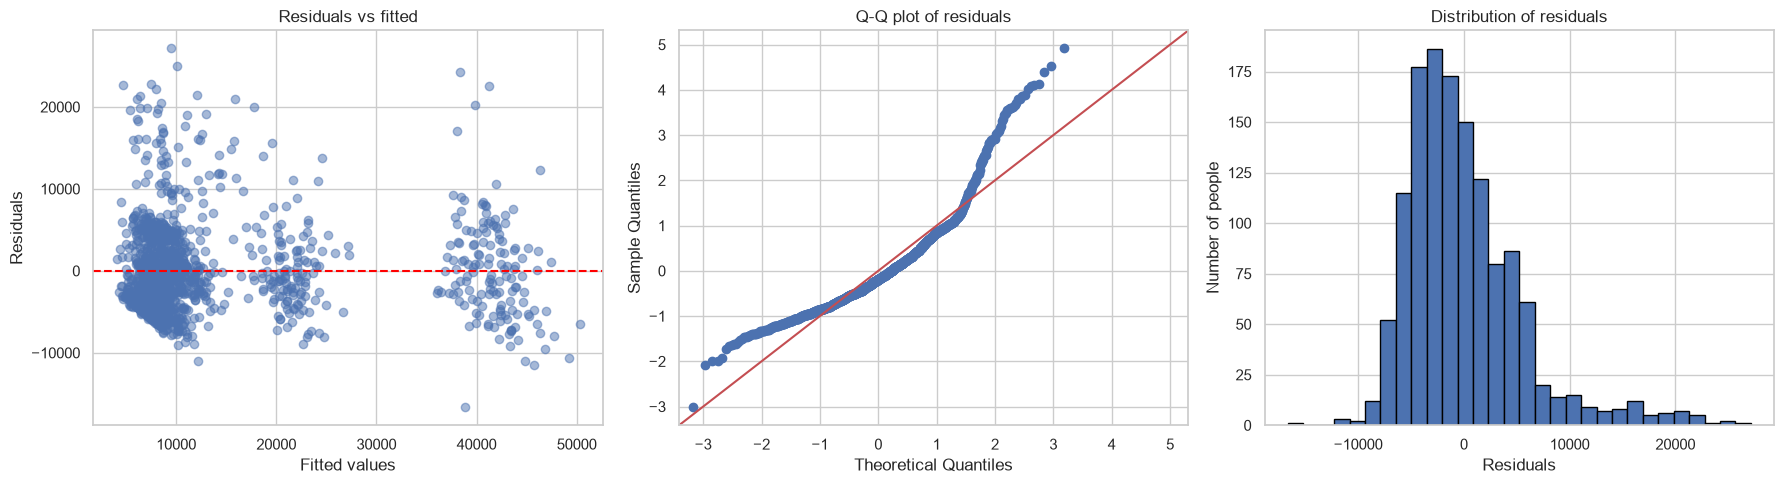

In [10]:
# Diagnostic plots for Model 2
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Residuals vs fitted: should be a shapeless cloud around 0
axes[0].scatter(model_2.fittedvalues, model_2.resid, alpha=0.5)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(xlabel="Fitted values", ylabel="Residuals", title="Residuals vs fitted")

# 2. Q-Q plot: points should follow the line if residuals are normal
sm.qqplot(model_2.resid, line="45", fit=True, ax=axes[1])
axes[1].set_title("Q-Q plot of residuals")

# 3. Histogram: should look roughly bell-shaped and centered on 0
axes[2].hist(model_2.resid, bins=30, edgecolor="black")
axes[2].set(xlabel="Residuals", ylabel="Number of people", title="Distribution of residuals")

plt.tight_layout()
plt.show()

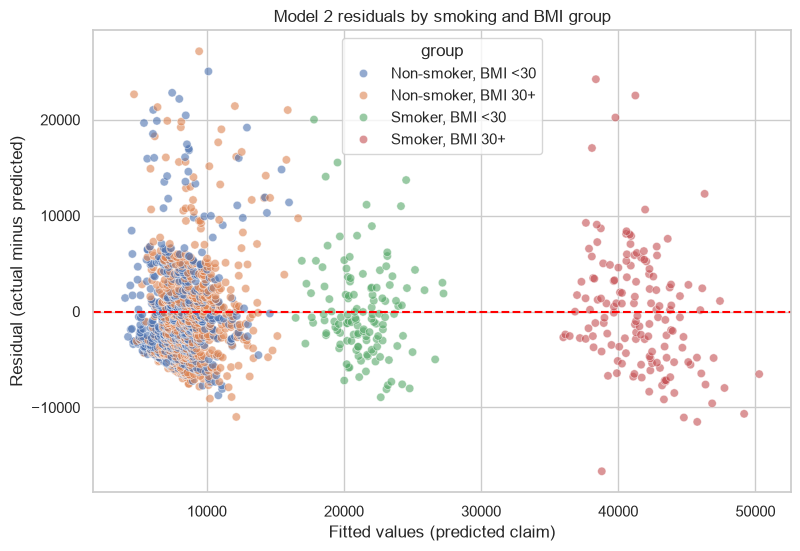

In [11]:
# Same residual plot, colored by smoking and BMI group
plt.figure(figsize=(9, 6))
sns.scatterplot(x=model_2.fittedvalues, y=model_2.resid, hue=df["group"], alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values (predicted claim)")
plt.ylabel("Residual (actual minus predicted)")
plt.title("Model 2 residuals by smoking and BMI group")
plt.show()

In [12]:
# Average and spread of the residuals in each group, in dollars
print(model_2.resid.groupby(df["group"]).agg(["count", "mean", "std"]).round(0))

print("Breusch-Pagan p:", round(het_breuschpagan(model_2.resid, model_2.model.exog)[1], 3))
print("Residual skewness:", round(model_2.resid.skew(), 2))

# People whose claim is more than 10,000 above their prediction, and how many are smokers
big_miss = model_2.resid > 10000
print("Claims more than 10,000 above prediction:", big_miss.sum())
print(df.loc[big_miss, "smoker"].value_counts())

                     count  mean     std
group                                   
Non-smoker, BMI 30+    557   0.0  5582.0
Non-smoker, BMI <30    501   0.0  5376.0
Smoker, BMI 30+        145   0.0  6315.0
Smoker, BMI <30        129   0.0  4899.0
Breusch-Pagan p: 0.185
Residual skewness: 1.48
Claims more than 10,000 above prediction: 73
smoker
False    61
True     12
Name: count, dtype: int64


| | Model 1 | Model 2 |
|---|---|---|
| Breusch-Pagan p | < 0.001 | 0.185 |
| Residual skewness | 0.98 | 1.48 |

- The residuals vs fitted plot now shows three clusters: non-smokers, smokers with BMI under 30, and smokers with BMI 30+. These are the three claim levels the model now predicts. Within each cluster, residuals are centered on zero with no bands, so the Model 1 pattern is gone.
- The spread is similar in every group (residual SD about 4,900 to 6,300). The Breusch-Pagan test no longer finds heteroscedasticity (p = 0.185).
- The Q-Q plot looks worse at the top. 73 people have claims more than 10,000 above their prediction, and 61 of them are non-smokers. These are the high-claim non-smokers seen in EDA, and none of the variables in the data explain them.
- The histogram is still centered on zero, with a long right tail.

Open question: do the skewed residuals change the confidence intervals?

## 3. Robustness check

The usual standard errors assume the residuals have the same spread everywhere. Robust standard errors (`cov_type="HC3"`) do not rely on that assumption. The coefficients stay the same; only the standard errors, confidence intervals and p-values are recalculated.

In [13]:
# Model 2 refit with robust standard errors
model_2_robust = smf.ols("claim ~ age + bmi + bloodpressure + children + diabetic + C(gender) + C(region) + smoker * bmi_30_plus", data=df).fit(cov_type="HC3")

# Standard errors and p-values side by side: usual vs robust
pd.DataFrame({
    "SE usual": model_2.bse,
    "SE robust": model_2_robust.bse,
    "p usual": model_2.pvalues,
    "p robust": model_2_robust.pvalues,
}).round(3)

,SE usual,SE robust,p usual,p robust
Intercept,1950.762,2326.659,0.000,0.001
diabetic[T.True],305.376,306.597,0.353,0.355
C(gender)[T.male],333.078,332.937,0.160,0.159
C(region)[T.northwest],475.048,494.318,0.000,0.000
C(region)[T.southeast],459.707,475.468,0.000,0.000
C(region)[T.southwest],485.431,497.786,0.000,0.000
smoker[T.True],555.799,519.910,0.000,0.000
age,14.951,15.198,0.529,0.536
bmi,42.229,44.121,0.000,0.000
bloodpressure,15.390,20.802,0.000,0.000


The standard errors change slightly, but no variable changes from significant to not significant, or the other way. The conclusions from Model 2 hold.

### Blood pressure (hypothesis 3)

EDA suggested blood pressure might add little once smoking and BMI were accounted for, since it overlapped with both. Model 2 does not support that. Holding the other variables constant, each point of blood pressure is still associated with about 137 more in expected claim (95% CI about 107 to 168).

That is smaller than in Model 1 (229 per point). Model 1 had one BMI slope for everyone, so blood pressure was partly picking up the BMI and smoking pattern. Once Model 2 handles BMI properly, blood pressure's own effect is smaller but still present.

## 4. Model 3: log of claim

Model 2's remaining problem is the long right tail of residuals. Taking the log of claim compresses large values, which often fixes that. R² and AIC cannot be compared with Model 2, because the outcome is on a different scale, so the two are compared on their diagnostics.

In [14]:
# Model 3: same variables as Model 2, but the outcome is log(claim)
model_3 = smf.ols("np.log(claim) ~ age + bmi + bloodpressure + children + diabetic + C(gender) + C(region) + smoker * bmi_30_plus", data=df).fit()
print(model_3.summary())

                            OLS Regression Results                            
Dep. Variable:          np.log(claim)   R-squared:                       0.554
Model:                            OLS   Adj. R-squared:                  0.550
Method:                 Least Squares   F-statistic:                     136.7
Date:                Wed, 07 Oct 2026   Prob (F-statistic):          1.76e-221
Time:                        09:44:44   Log-Likelihood:                -1227.0
No. Observations:                1332   AIC:                             2480.
Df Residuals:                    1319   BIC:                             2547.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

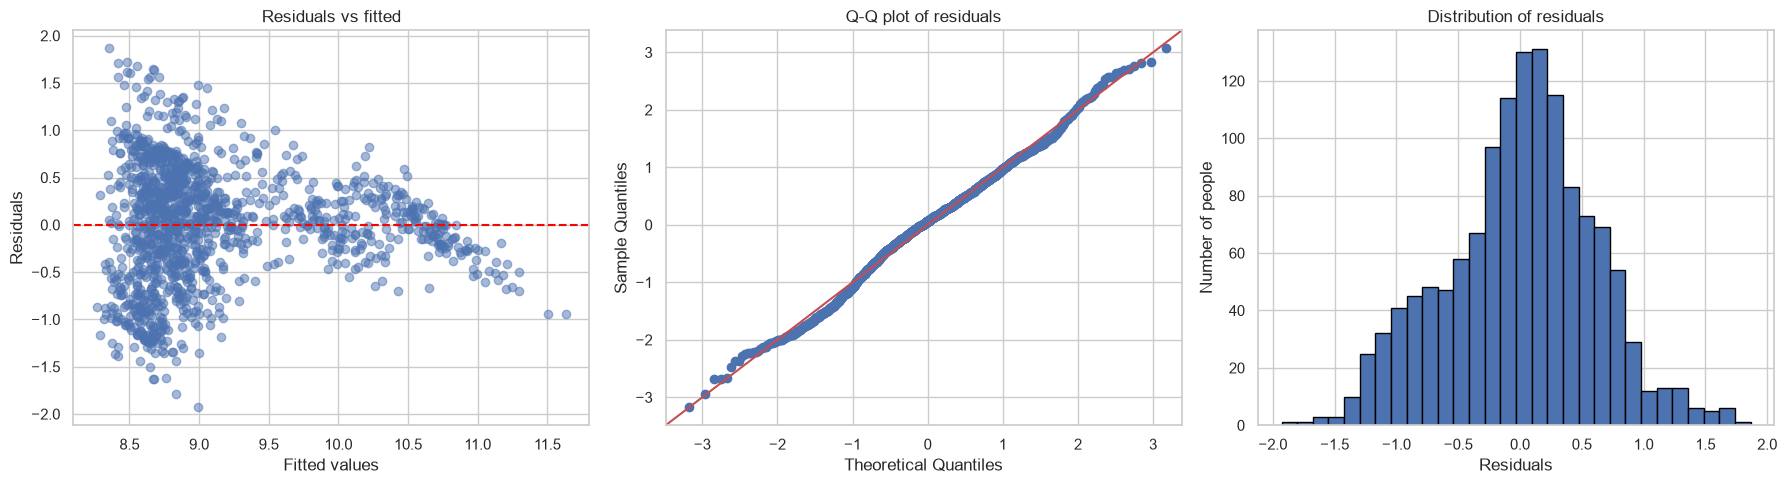

In [15]:
# Diagnostic plots for Model 3
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Residuals vs fitted: should be a shapeless cloud around 0
axes[0].scatter(model_3.fittedvalues, model_3.resid, alpha=0.5)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(xlabel="Fitted values", ylabel="Residuals", title="Residuals vs fitted")

# 2. Q-Q plot: points should follow the line if residuals are normal
sm.qqplot(model_3.resid, line="45", fit=True, ax=axes[1])
axes[1].set_title("Q-Q plot of residuals")

# 3. Histogram: should look roughly bell-shaped and centered on 0
axes[2].hist(model_3.resid, bins=30, edgecolor="black")
axes[2].set(xlabel="Residuals", ylabel="Number of people", title="Distribution of residuals")

plt.tight_layout()
plt.show()

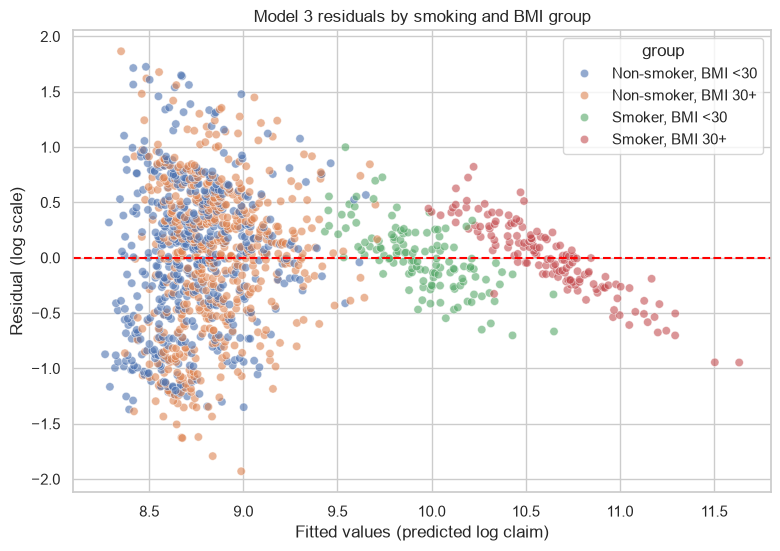

In [16]:
# Same residual plot, colored by smoking and BMI group
plt.figure(figsize=(9, 6))
sns.scatterplot(x=model_3.fittedvalues, y=model_3.resid, hue=df["group"], alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values (predicted log claim)")
plt.ylabel("Residual (log scale)")
plt.title("Model 3 residuals by smoking and BMI group")
plt.show()

In [17]:
print("Breusch-Pagan p:", round(het_breuschpagan(model_3.resid, model_3.model.exog)[1], 3))
print("Residual skewness:", round(model_3.resid.skew(), 2))

# Spread of the residuals in each group (log scale)
print(model_3.resid.groupby(df["group"]).std().round(2))

# A log-model coefficient becomes a % change with exp(coef) - 1
print("Smoker (BMI under 30), % change:", round((np.exp(model_3.params["smoker[T.True]"]) - 1) * 100))

Breusch-Pagan p: 0.0
Residual skewness: -0.11
group
Non-smoker, BMI 30+    0.67
Non-smoker, BMI <30    0.66
Smoker, BMI 30+        0.32
Smoker, BMI <30        0.30
dtype: float64
Smoker (BMI under 30), % change: 199


| | Model 2 (claim) | Model 3 (log claim) |
|---|---|---|
| Residual skewness | 1.48 | -0.11 |
| Breusch-Pagan p | 0.185 | < 0.001 |

- The Q-Q plot is now close to a straight line and the histogram is symmetric. The log fixed the right tail.
- But heteroscedasticity is back. Non-smokers' residuals are about twice as spread out as smokers' (SD about 0.66 vs 0.30), because the log stretches small claims apart and squeezes large ones together.
- Within the smoker groups, residuals slope downward: the model predicts too low for lower-claim smokers and too high for the highest ones. A log model treats effects as percentages that multiply together, while in this data they seem to add up in dollars.
- Coefficients are now percentage changes (exp(coef) - 1). For example, smokers with BMI under 30 have about 199% higher expected claims than similar non-smokers, roughly three times as much.
- Gender is significant here (p = 0.038) but not in Models 1 or 2. Because it depends on the model choice, it is treated as weak evidence.

Decision so far: Model 3 fixes one problem but creates two others, so Model 2 is preferred.

Open question: a gamma GLM is the standard model for claim amounts in insurance. Does it do better?

## 5. Gamma GLMs

A gamma GLM assumes the spread of claims grows with their size, so high-cost smokers would vary more than low-cost non-smokers. The link function decides how the variables combine: a log link multiplies effects (like Model 3), and an identity link adds them in dollars (like Model 2). Both versions use the same variables as Model 2.

In [18]:
# Gamma GLM, log link: effects multiply (coefficients are % changes, like Model 3)
gamma_log = smf.glm(
    "claim ~ age + bmi + bloodpressure + children + diabetic + C(gender) + C(region) + smoker * bmi_30_plus",
    data=df,
    family=sm.families.Gamma(link=sm.families.links.Log()),
).fit()
print(gamma_log.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  claim   No. Observations:                 1332
Model:                            GLM   Df Residuals:                     1319
Model Family:                   Gamma   Df Model:                           12
Link Function:                    Log   Scale:                         0.38225
Method:                          IRLS   Log-Likelihood:                -13374.
Date:                Wed, 07 Oct 2026   Deviance:                       471.07
Time:                        09:44:44   Pearson chi2:                     504.
No. Iterations:                    17   Pseudo R-squ. (CS):             0.6711
Covariance Type:            nonrobust                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

In [19]:
# Gamma GLM, identity link: effects add up in dollars (like Model 2)
# statsmodels warns that this link could in principle predict a negative claim; all predictions here are positive
gamma_identity = smf.glm(
    "claim ~ age + bmi + bloodpressure + children + diabetic + C(gender) + C(region) + smoker * bmi_30_plus",
    data=df,
    family=sm.families.Gamma(link=sm.families.links.Identity()),
).fit()
print(gamma_identity.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  claim   No. Observations:                 1332
Model:                            GLM   Df Residuals:                     1319
Model Family:                   Gamma   Df Model:                           12
Link Function:               Identity   Scale:                         0.38905
Method:                          IRLS   Log-Likelihood:                -13359.
Date:                Wed, 07 Oct 2026   Deviance:                       457.80
Time:                        09:44:44   Pearson chi2:                     513.
No. Iterations:                    25   Pseudo R-squ. (CS):             0.6732
Covariance Type:            nonrobust                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

/Users/hugoortega/.virtualenvs/insurance-claims/lib/python3.14/site-packages/statsmodels/base/model.py:243: DomainWarning: The Identity link function does not respect the domain of the Gamma family.
  mod = cls(endog, exog, *args, **kwargs)


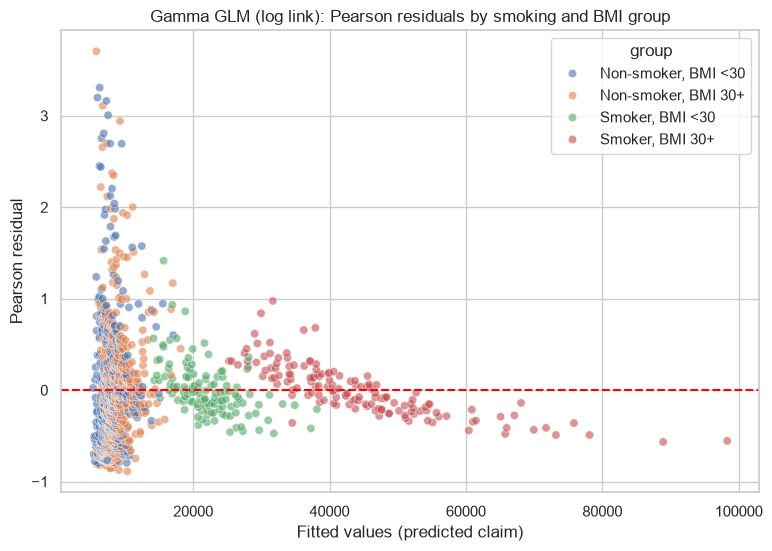

In [20]:
# Pearson residuals for the gamma GLM (log link)
# They are scaled by the spread the gamma model expects at each predicted value,
# so if the variance assumption is right they form an even band around 0
plt.figure(figsize=(9, 6))
sns.scatterplot(x=gamma_log.fittedvalues, y=gamma_log.resid_pearson, hue=df["group"], alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values (predicted claim)")
plt.ylabel("Pearson residual")
plt.title("Gamma GLM (log link): Pearson residuals by smoking and BMI group")
plt.show()

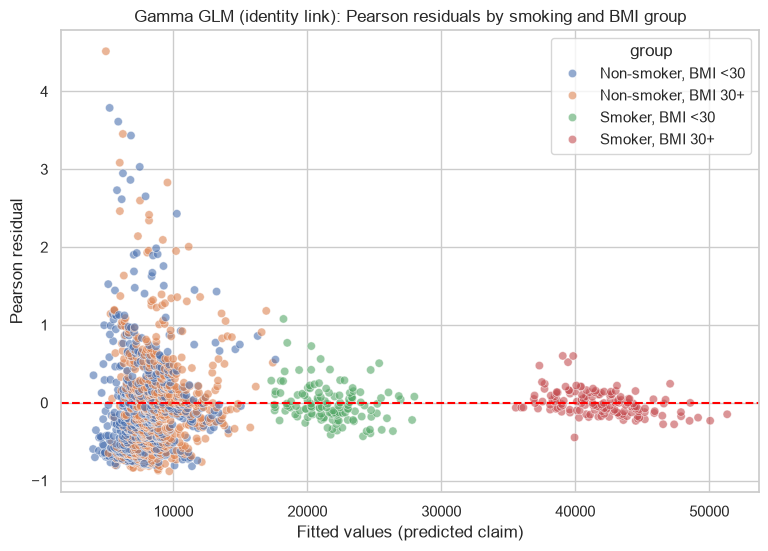

In [21]:
# Pearson residuals for the gamma GLM (identity link)
plt.figure(figsize=(9, 6))
sns.scatterplot(x=gamma_identity.fittedvalues, y=gamma_identity.resid_pearson, hue=df["group"], alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values (predicted claim)")
plt.ylabel("Pearson residual")
plt.title("Gamma GLM (identity link): Pearson residuals by smoking and BMI group")
plt.show()

In [22]:
# Largest prediction from the log-link model, that person's actual claim, and the largest claim in the data
top = gamma_log.fittedvalues.idxmax()
print("Largest prediction (log link):", round(gamma_log.fittedvalues.max()))
print("That person's actual claim:", round(df.loc[top, "claim"]))
print("Largest claim in the data:", round(df["claim"].max()))
print("Largest prediction (identity link):", round(gamma_identity.fittedvalues.max()))

# Spread of the Pearson residuals in each group (equal spread = variance assumption fits)
pd.DataFrame({
    "log link": gamma_log.resid_pearson.groupby(df["group"]).std(),
    "identity link": gamma_identity.resid_pearson.groupby(df["group"]).std(),
}).round(2)

Largest prediction (log link): 98305
That person's actual claim: 43753
Largest claim in the data: 63770
Largest prediction (identity link): 51337


,log link,identity link
group,,
"Non-smoker, BMI 30+",0.65,0.67
"Non-smoker, BMI <30",0.70,0.71
"Smoker, BMI 30+",0.28,0.16
"Smoker, BMI <30",0.29,0.24


In [23]:
# Model 2 vs identity-link gamma: coefficients and p-values side by side
pd.DataFrame({
    "Model 2 coef": model_2.params,
    "Gamma coef": gamma_identity.params,
    "Model 2 p": model_2.pvalues,
    "Gamma p": gamma_identity.pvalues,
}).round(3)

,Model 2 coef,Gamma coef,Model 2 p,Gamma p
Intercept,-7844.974,-6587.491,0.000,0.003
diabetic[T.True],-283.654,-160.897,0.353,0.584
C(gender)[T.male],-468.398,-169.146,0.160,0.594
C(region)[T.northwest],-2210.835,-3508.452,0.000,0.000
C(region)[T.southeast],-3201.655,-3875.082,0.000,0.000
C(region)[T.southwest],-2724.997,-3020.053,0.000,0.000
smoker[T.True],12380.706,12537.863,0.000,0.000
age,9.403,19.977,0.529,0.167
bmi,186.100,88.486,0.000,0.034
bloodpressure,137.449,150.573,0.000,0.000


- Log link: some predictions run away. The largest is 98,305 for a person whose actual claim was 43,753, while the largest claim in the data is 63,770. This stretches the x-axis. Smokers' residuals slope downward, the same banding as Model 3.
- Identity link: the banding is gone, and predictions stay in a sensible range (up to 51,337).
- In both versions, smokers' Pearson residuals are much tighter than non-smokers' (SD about 0.16 to 0.29 for smokers vs 0.65 to 0.71 for non-smokers). The gamma expected smokers to vary much more than they do. In dollars, Model 2's residual spread is similar in every group, which fits OLS's assumption better.
- The identity-link gamma gives the same conclusions as Model 2: the same variables are significant, and the main effects are close (smoker +12,538 vs +12,380, interaction +17,709 vs +17,750).

Decision: Model 2 stays the final model. The gamma results are a second robustness check, and they support Model 2's conclusions.

## 6. Summary: what the hypotheses showed

The final model is Model 2 (claim in dollars, with the smoking × BMI 30+ interaction). Every number below comes from that model, with the other variables held constant.

| Hypothesis from EDA | Result | Evidence from Model 2 |
|---|---|---|
| 1. Smoking is the strongest factor | Supported | Smokers with BMI under 30: +12,380 |
| 2. Smoking and BMI 30+ interact | Supported | Interaction: +17,750 (95% CI 16,200 to 19,300). Together, an obese smoker's expected claim is about 29,300 higher than a non-smoker under BMI 30. |
| 3. Blood pressure adds little once smoking and BMI are included | Not supported | Smaller than in Model 1, but still significant: +137 per point (95% CI 107 to 168) |
| 4. The northeast has higher claims | Supported | Other regions are about 2,200 to 3,200 lower than the northeast |
| 5. Age shows little association | Supported | +9 per year, not significant (p = 0.53) |
| 6. Gender, diabetic status and children show little association | Partly supported | Gender (p = 0.16) and diabetic (p = 0.35) are not significant. Children is significant: about +694 per child (95% CI 446 to 942). |

What stood out:

- Smoking stands out the most, and its association with claims is even larger together with a BMI of 30 or more. For non-smokers, a BMI of 30 or more is not significant.
- Two results went against EDA. Blood pressure is still significant after accounting for smoking and BMI, and children is significant once smoking is held constant. In EDA, smokers' large claims hid the children pattern.
- Age, gender and diabetic status show no evidence of an association with claims. That does not prove they have no effect, only that this data cannot tell their effect apart from zero.
- The results held up under robust standard errors and in a gamma GLM.
- These are associations in data that may be synthetic, not proof that smoking or BMI cause higher claims.